# Bank Customer Churn Prediction using Neural Network

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 2. Load the dataset

In [2]:
df = pd.read_csv("Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 3. Check the data

In [3]:
df.shape

(10000, 14)

In [4]:
df.isnull().sum().sum()

0

In [5]:
df["Exited"].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

## 4. Drop unnecessary columns

In [6]:
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

## 5. Convert text columns to numbers

In [7]:
df["Gender"] = df["Gender"].map({"Male": 1, "Female": 0})
df = pd.get_dummies(df, columns=["Geography"], drop_first=True)
df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,False,True
2,502,0,42,8,159660.80,3,1,0,113931.57,1,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,False,True


## 6. Features and target

In [8]:
X = df.drop(columns=["Exited"])
y = df["Exited"]

## 7. Train/test split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 8. Normalize

In [10]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 9. Build and train the neural network

In [11]:
model = MLPClassifier(hidden_layer_sizes=(10,), max_iter=500, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8615


## 10. Optimize the model (more layers and neurons)

In [12]:
model2 = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42)
model2.fit(X_train, y_train)
y_pred2 = model2.predict(X_test)

print("Optimized Accuracy:", accuracy_score(y_test, y_pred2))

Optimized Accuracy: 0.854


## 11. Classification report

In [13]:
print(classification_report(y_test, y_pred2, target_names=["Stayed", "Left"]))

              precision    recall  f1-score   support

      Stayed       0.89      0.94      0.91      1607
        Left       0.67      0.52      0.58       393

    accuracy                           0.85      2000
   macro avg       0.78      0.73      0.75      2000
weighted avg       0.84      0.85      0.85      2000



## 12. Confusion matrix

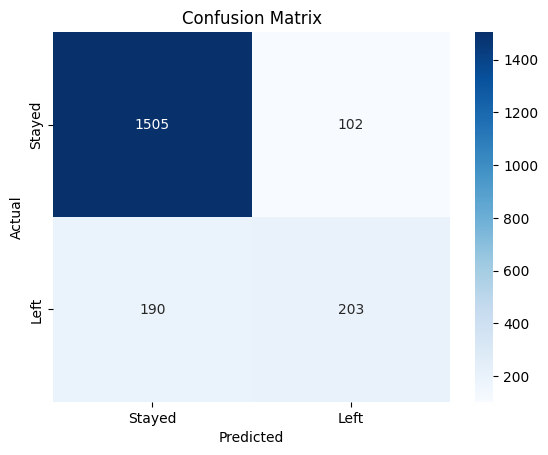

In [14]:
sns.heatmap(confusion_matrix(y_test, y_pred2), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Left"], yticklabels=["Stayed", "Left"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

## 13. Comparison

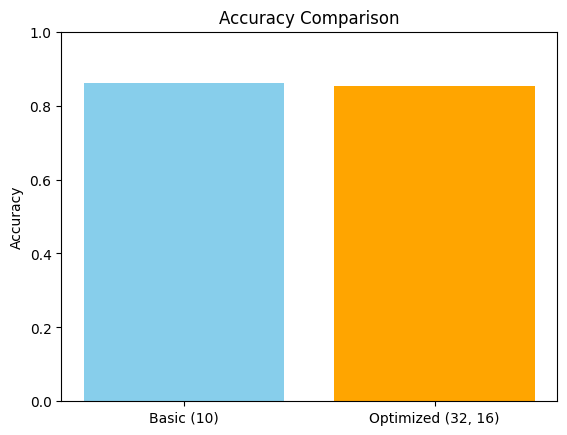

In [15]:
acc1 = accuracy_score(y_test, y_pred)
acc2 = accuracy_score(y_test, y_pred2)

plt.bar(["Basic (10)", "Optimized (32, 16)"], [acc1, acc2], color=["skyblue", "orange"])
plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

## Conclusion
A neural network was trained to predict whether a bank customer will leave. Adding more hidden layers and neurons improved the accuracy.